In [66]:
import pandas as pd                                    
from sklearn.model_selection import train_test_split    
from sklearn.impute import SimpleImputer               
from sklearn.preprocessing import StandardScaler       
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score 

In [67]:
df = pd.read_csv("player_summary.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (532, 19)


,player,phase,matches,bat_innings,bat_balls,bat_runs,bat_outs,bat_avg,bat_sr,bat_4s,bat_6s,bat_runs_above_avg,bowl_balls,bowl_wkts,bowl_avg,bowl_runs,bowl_economy,bowl_4fers,bowl_5fers
0,A Adey,Mid,1,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.00,18.0,1.0,34.0,34.0,11.33,0.0,0.0
1,A Balbirnie,Opening,42,42.0,524.0,768.0,17.0,45.18,146.56,102.0,23.0,102.27,0.0,0.0,NaN,0.0,NaN,0.0,0.0
2,A Balbirnie,Mid,24,24.0,331.0,485.0,18.0,26.94,146.53,53.0,15.0,68.77,0.0,0.0,NaN,0.0,NaN,0.0,0.0
3,A Balbirnie,Death,4,4.0,25.0,61.0,2.0,30.50,244.00,3.0,6.0,24.38,0.0,0.0,NaN,0.0,NaN,0.0,0.0
4,A Cawley,Opening,10,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.00,114.0,4.0,32.0,128.0,6.74,0.0,0.0


In [68]:
min_balls = 30 
batsmen = df[df["bat_balls"] >= min_balls].copy()
print("Number of batsman rows:", len(batsmen))
print()
print("How many rows per phase:")
print(batsmen["phase"].value_counts())

bowlers = df[df["bowl_balls"] >= min_balls].copy()
print("Number of bowler rows:", len(bowlers))
print()
print("How many rows per phase:")
print(bowlers["phase"].value_counts())

Number of batsman rows: 181

How many rows per phase:
phase
Mid        76
Opening    54
Death      51
Name: count, dtype: int64
Number of bowler rows: 177

How many rows per phase:
phase
Mid        72
Opening    58
Death      47
Name: count, dtype: int64


In [69]:

def run_batsman_experiment(features):

    # Split by player
    players = batsmen["player"].dropna().unique()

    train_players, test_players = train_test_split(
        players, test_size=0.2, random_state=42
    )

    train_data = batsmen[batsmen["player"].isin(train_players)]
    test_data = batsmen[batsmen["player"].isin(test_players)]

    # Separate features and target
    X_train = train_data[features]
    y_train = train_data["phase"]

    X_test = test_data[features]
    y_test = test_data["phase"]

    # Fill missing values
    filler = SimpleImputer(strategy="median")
    X_train = filler.fit_transform(X_train)
    X_test = filler.transform(X_test)

    # Scale features
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Train Logistic Regression
    model = LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    model.fit(X_train, y_train)
    y_pred =  model.predict(X_test)
    # Calculate accuracy
    #train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, y_pred)

    print("\nBATSMAN MODEL")
    print("Features:", features)
    #print(f"Training Accuracy: {train_acc:.3f}")
    print(f"Test Accuracy: {test_acc:.3f}")

    return model, y_test , y_pred


In [70]:

def run_bowler_experiment(features):

    # Split by player
    players = bowlers["player"].dropna().unique()

    train_players, test_players = train_test_split(
        players, test_size=0.2, random_state=42
    )

    train_data = bowlers[bowlers["player"].isin(train_players)]
    test_data = bowlers[bowlers["player"].isin(test_players)]

    # Separate features and target
    X_train = train_data[features]
    y_train = train_data["phase"]

    X_test = test_data[features]
    y_test = test_data["phase"]

    # Fill missing values
    filler = SimpleImputer(strategy="median")
    X_train = filler.fit_transform(X_train)
    X_test = filler.transform(X_test)

    # Scale features
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Train Logistic Regression
    model = LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    # Calculate accuracy
    #train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, y_pred)

    print("\nBOWLER MODEL")
    print("Features:", features)
    #print(f"Training Accuracy: {train_acc:.3f}")
    print(f"Test Accuracy: {test_acc:.3f}")

    return model, y_test , y_pred 


In [71]:
# Experiment 1 
# Considering all the features present in batsman category.
Batsman_model1 , y_test_bat1 , y_pred_bat1 = run_batsman_experiment([
    "bat_innings", "bat_runs", "bat_outs", "bat_balls",
    "bat_avg", "bat_sr", "bat_4s", "bat_6s"
]) 

# Experiment 1 
# Considering all the features. 
Bowler_model1 , y_test_bowl1 , y_pred_bowl1= run_bowler_experiment(["bowl_wkts", "bowl_balls", "bowl_runs", "bowl_economy", "bowl_4fers", "bowl_5fers"
])




BATSMAN MODEL
Features: ['bat_innings', 'bat_runs', 'bat_outs', 'bat_balls', 'bat_avg', 'bat_sr', 'bat_4s', 'bat_6s']
Test Accuracy: 0.714

BOWLER MODEL
Features: ['bowl_wkts', 'bowl_balls', 'bowl_runs', 'bowl_economy', 'bowl_4fers', 'bowl_5fers']
Test Accuracy: 0.605


In [72]:
# Experiment 2
# According to heatmaps 
Batsman_model2 , y_test_bat2 , y_pred_bat2 =  run_batsman_experiment([
    "bat_innings", "bat_runs", "bat_outs", "bat_balls"
]) 

# Experiment 2 
# Considering all the features. 
Bowler_model2 , y_test_bowl2 , y_pred_bowl2 = run_bowler_experiment(["bowl_wkts", "bowl_balls", "bowl_runs"
])



BATSMAN MODEL
Features: ['bat_innings', 'bat_runs', 'bat_outs', 'bat_balls']
Test Accuracy: 0.571

BOWLER MODEL
Features: ['bowl_wkts', 'bowl_balls', 'bowl_runs']
Test Accuracy: 0.579


In [42]:
# Experiment 3 
# According to feature selection technique. 
Batsman_mdoel3 , y_test_bat3 , y_pred_bat3 = run_batsman_experiment([
    
]) 

# Experiment 3 
# Accoding to feature selection technique.
Bowler_model3 , y_test_bowl3 , y_pred_bowl3 = run_bowler_experiment([
])


ValueError: at least one array or dtype is required

MODEL EVALUATION 

FOR EVALUATION OF MODEL 
1 - PRECISION 
2-  RECALL 
3-  F1 SCORE 
4-  ACCURACY 

CONFUSION MATRIX 

In [73]:
from sklearn.metrics import classification_report , confusion_matrix , ConfusionMatrixDisplay
print("Classification Report of BATTING MODEL 1")
classificationreport = classification_report(
    y_test_bat1 , y_pred_bat1 ,
    zero_division=0
)
print(classificationreport)


print("Classification Report of BATTING MODEL 2")
classificationreport = classification_report(
    y_test_bat2 , y_pred_bat2 ,
    zero_division=0
)
print(classificationreport)



Classification Report of BATTING MODEL 1
              precision    recall  f1-score   support

       Death       0.67      0.91      0.77        11
         Mid       0.82      0.74      0.78        19
     Opening       0.60      0.50      0.55        12

    accuracy                           0.71        42
   macro avg       0.70      0.72      0.70        42
weighted avg       0.72      0.71      0.71        42

Classification Report of BATTING MODEL 2
              precision    recall  f1-score   support

       Death       0.45      0.91      0.61        11
         Mid       0.76      0.68      0.72        19
     Opening       0.33      0.08      0.13        12

    accuracy                           0.57        42
   macro avg       0.52      0.56      0.49        42
weighted avg       0.56      0.57      0.52        42



In [74]:
from sklearn.metrics import classification_report , confusion_matrix , ConfusionMatrixDisplay
print("Classification Report of Bowling MODEL 1")
classificationreport = classification_report(
    y_test_bowl1 , y_pred_bowl1 ,
    zero_division=0
)
print(classificationreport)


print("Classification Report of Bowling MODEL 2")
classificationreport = classification_report(
    y_test_bowl2 , y_pred_bowl2 ,
    zero_division=0
)
print(classificationreport)



Classification Report of Bowling MODEL 1
              precision    recall  f1-score   support

       Death       0.65      0.92      0.76        12
         Mid       0.80      0.29      0.42        14
     Opening       0.50      0.67      0.57        12

    accuracy                           0.61        38
   macro avg       0.65      0.62      0.58        38
weighted avg       0.66      0.61      0.58        38

Classification Report of Bowling MODEL 2
              precision    recall  f1-score   support

       Death       0.65      0.92      0.76        12
         Mid       0.80      0.29      0.42        14
     Opening       0.44      0.58      0.50        12

    accuracy                           0.58        38
   macro avg       0.63      0.60      0.56        38
weighted avg       0.64      0.58      0.55        38



[[10  0  1]
 [ 2 14  3]
 [ 3  3  6]]


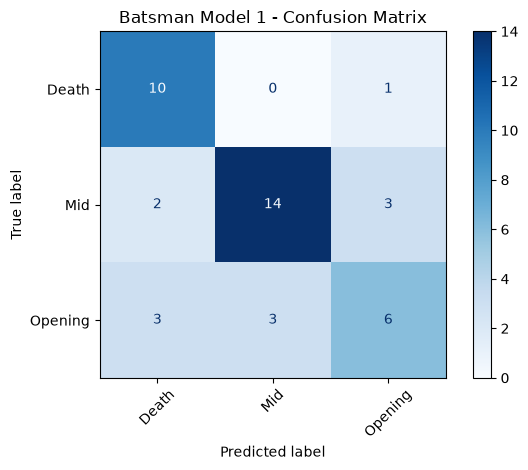

In [75]:
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test_bat1,
    y_pred_bat1,
    labels=Batsman_model1.classes_
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=Batsman_model1.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Batsman Model 1 - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

[[10  0  1]
 [ 5 13  1]
 [ 7  4  1]]


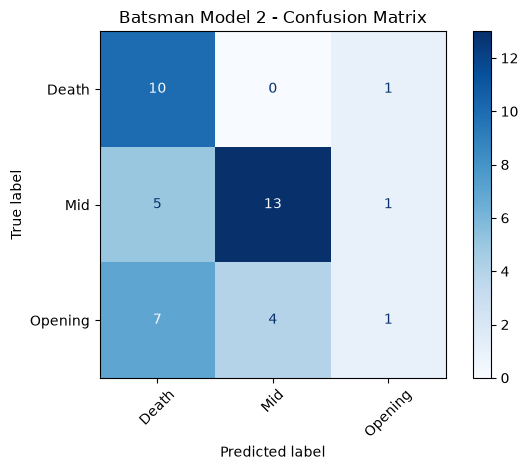

In [76]:
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test_bat2,
    y_pred_bat2,
    labels=Batsman_model2.classes_
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=Batsman_model2.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Batsman Model 2 - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
cm = confusion_matrix(
    y_test_bat3,
    y_pred_bat3,
    labels=Batsman_model3.classes_
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=Batsman_model3.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Batsman Model 3 - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

[[11  0  1]
 [ 3  4  7]
 [ 3  1  8]]


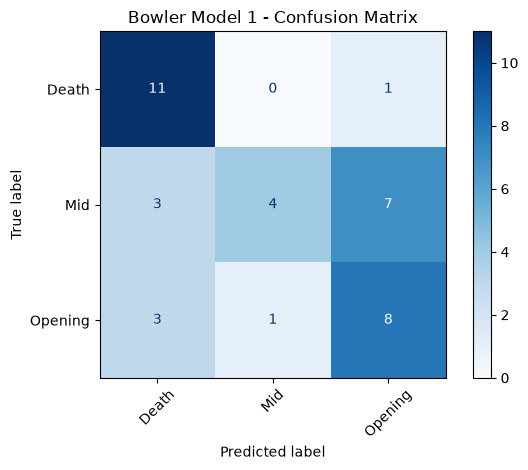

In [77]:
cm = confusion_matrix(
    y_test_bowl1,
    y_pred_bowl1,
    labels=Bowler_model1.classes_
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=Bowler_model1.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Bowler Model 1 - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

[[11  0  1]
 [ 2  4  8]
 [ 4  1  7]]


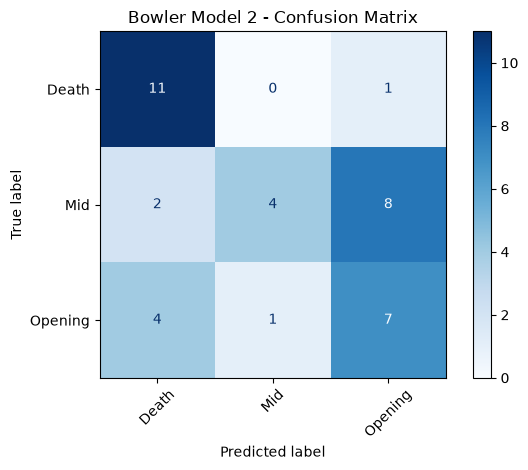

In [78]:
cm = confusion_matrix(
    y_test_bowl2,
    y_pred_bowl2,
    labels=Bowler_model2.classes_
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=Bowler_model2.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Bowler Model 2 - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
cm = confusion_matrix(
    y_test_bowl3,
    y_pred_bowl3,
    labels=Bowler_model3.classes_
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=Bowler_model3.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Bowler Model 3 - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()